# Session 32 Solutions: How Models Learn: Gradient Descent

Data Science with Python, Level 2, Stage 5: ML Fundamentals

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, SGDRegressor

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
x = exams["study_hours_week"].to_numpy()
y = exams["math"].to_numpy(dtype=float)

## In-Class Exercises

### In-Class Exercise 1: Loss of the Mean

In [2]:
base = np.mean((y - y.mean()) ** 2)
sk = LinearRegression().fit(x.reshape(-1, 1), y)
best = np.mean((y - sk.predict(x.reshape(-1, 1))) ** 2)
print(round(base, 1), round(best, 1), round(1 - best / base, 3))

176.1 138.0 0.216


### In-Class Exercise 2: Plot the Descent

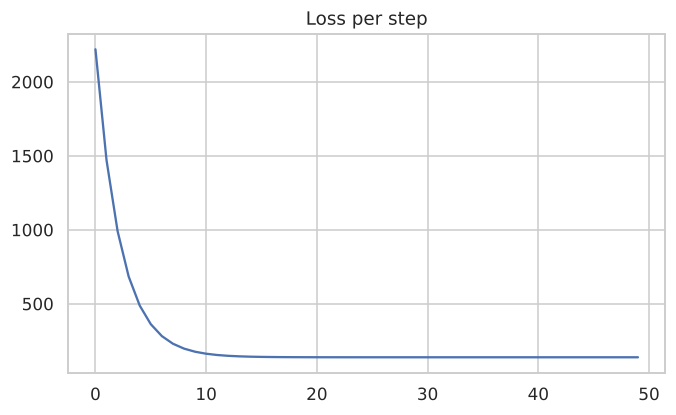

In [3]:
x_std = (x - x.mean()) / x.std()
w, b, losses = 0.0, 0.0, []
for _ in range(50):
    error = y - (w * x_std + b)
    w += 0.1 * 2 * np.mean(x_std * error)
    b += 0.1 * 2 * np.mean(error)
    losses.append(np.mean((y - (w * x_std + b)) ** 2))
plt.plot(losses)
plt.title("Loss per step")
plt.show()

### In-Class Exercise 3: Find the Breaking Point

In [4]:
x_std = (x - x.mean()) / x.std()
for lr in [0.5, 0.9, 1.0, 1.1]:
    w, b = 0.0, 0.0
    for _ in range(50):
        error = y - (w * x_std + b)
        w += lr * 2 * np.mean(x_std * error)
        b += lr * 2 * np.mean(error)
    print(lr, round(np.mean((y - (w * x_std + b)) ** 2), 1))

0.5 138.0
0.9 138.0
1.0 3391.6
1.1 269456888920.5


### In-Class Exercise 4: Two Features

In [5]:
X = exams[["study_hours_week", "sleep_hours"]].to_numpy()
Xs = (X - X.mean(axis=0)) / X.std(axis=0)
w, b = np.zeros(2), 0.0
for _ in range(500):
    error = y - (Xs @ w + b)
    w += 0.1 * 2 * (Xs.T @ error) / len(y)
    b += 0.1 * 2 * error.mean()
print(w.round(3), round(b, 2))
print(LinearRegression().fit(Xs, y).coef_.round(3))

[6.042 2.508] 56.71
[6.042 2.508]


## Part A: Basic

### Exercise 1: Compute a Loss

In [6]:
def mae(w, b):
    return np.mean(np.abs(y - (w * x + b)))

print(round(mae(1.5, 46), 2), round(mae(0, 57), 2))

9.26 10.41


### Exercise 2: Loss Valley for b

46.4


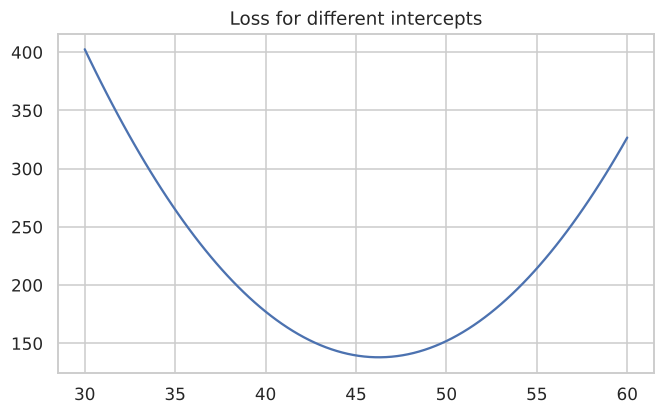

In [7]:
def mse(w, b):
    return np.mean((y - (w * x + b)) ** 2)

bs = np.linspace(30, 60, 100)
losses = [mse(1.52, b) for b in bs]
plt.plot(bs, losses)
plt.title("Loss for different intercepts")
plt.show()
print(round(bs[np.argmin(losses)], 1))

## Part B: Intermediate

### Exercise 3: Gradient Descent for Rentals

Converting back: the slope divides by the std, and the intercept shifts by the slope times the mean.

In [8]:
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
t = bikes["temp_c"].to_numpy()
r = bikes["rentals"].to_numpy(dtype=float)
ts = (t - t.mean()) / t.std()
w, b = 0.0, 0.0
for _ in range(300):
    error = r - (w * ts + b)
    w += 0.1 * 2 * np.mean(ts * error)
    b += 0.1 * 2 * np.mean(error)
slope = w / t.std()
intercept = b - slope * t.mean()
print(round(slope, 2), round(intercept, 1))
sk = LinearRegression().fit(t.reshape(-1, 1), r)
print(round(sk.coef_[0], 2), round(sk.intercept_, 1))

152.22 1724.9
152.22 1724.9


### Exercise 4: Mini-Batch Descent

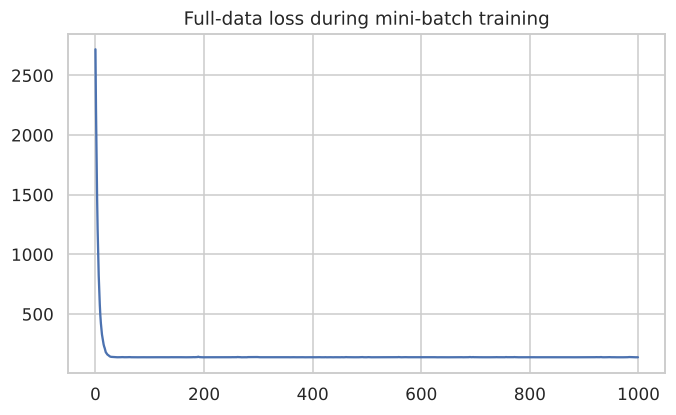

In [9]:
rng = np.random.default_rng(32)
x_std = (x - x.mean()) / x.std()
w, b, losses = 0.0, 0.0, []
for _ in range(1000):
    idx = rng.choice(len(y), 32, replace=False)
    error = y[idx] - (w * x_std[idx] + b)
    w += 0.05 * 2 * np.mean(x_std[idx] * error)
    b += 0.05 * 2 * np.mean(error)
    losses.append(np.mean((y - (w * x_std + b)) ** 2))
plt.plot(losses)
plt.title("Full-data loss during mini-batch training")
plt.show()
# Each step sees only 32 students, so the gradient is a noisy estimate and the loss jumps around while falling.

## Part C: Challenge

### Exercise 5: Gradient Descent with Many Features

In [10]:
def fit_gd(X, y, lr=0.1, steps=1000):
    X = np.asarray(X, dtype=float)
    Xs = (X - X.mean(axis=0)) / X.std(axis=0)
    w, b, losses = np.zeros(X.shape[1]), 0.0, []
    for _ in range(steps):
        error = y - (Xs @ w + b)
        w += lr * 2 * (Xs.T @ error) / len(y)
        b += lr * 2 * error.mean()
        losses.append(np.mean(error ** 2))
    return w, b, losses

flats = pd.read_csv(DATA_URL + "apartments.csv")
cols = ["area_m2", "building_age", "distance_center_km"]
w, b, losses = fit_gd(flats[cols], flats["price_k"].to_numpy())
print(w.round(2), round(b, 2))
Xs = (flats[cols] - flats[cols].mean()) / flats[cols].std(ddof=0)
print(LinearRegression().fit(Xs, flats["price_k"]).coef_.round(2))

[ 26.88  -8.17 -20.96] 98.69
[ 26.88  -8.17 -20.96]


## Part D: Cumulative Project: Apartment Prices

### Exercise 6: Apartment Prices: Inside the Model

Ours, original units: [ 0.849  2.297 -0.631 -7.791]
scikit-learn:         [ 0.849  2.297 -0.631 -7.791]


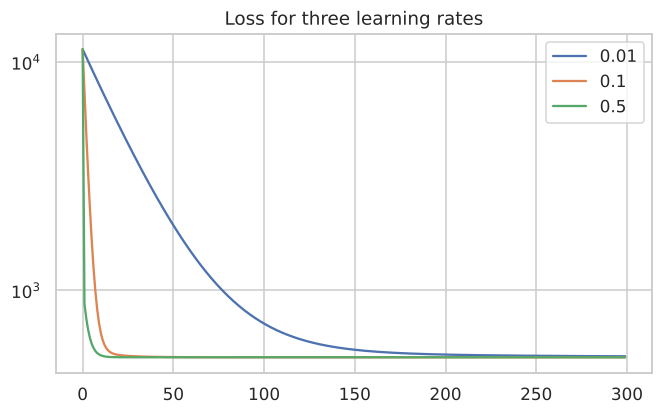

In [11]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
cols = ["area_m2", "rooms", "building_age", "distance_center_km"]
X = flats[cols].to_numpy(dtype=float)
yy = flats["price_k"].to_numpy()
mean, std = X.mean(axis=0), X.std(axis=0)
Xs = (X - mean) / std

def run(lr, steps=300):
    w, b, losses = np.zeros(4), 0.0, []
    for _ in range(steps):
        error = yy - (Xs @ w + b)
        w += lr * 2 * (Xs.T @ error) / len(yy)
        b += lr * 2 * error.mean()
        losses.append(np.mean(error ** 2))
    return w, b, losses

for lr in [0.01, 0.1, 0.5]:
    plt.plot(run(lr)[2], label=str(lr))
plt.yscale("log")
plt.legend()
plt.title("Loss for three learning rates")
plt.show()
w, b, _ = run(0.1)
print("Ours, original units:", (w / std).round(3))
print("scikit-learn:        ", LinearRegression().fit(X, yy).coef_.round(3))
# Standardised weights measure the effect of a one-standard-deviation change, so all features are on the same scale.
# Raw coefficients depend on the units: a coefficient per square metre and one per kilometre cannot be compared directly.

## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Training tries to make the loss as small as possible. |
| 2 | B | Step against the gradient: a positive gradient means decrease w. |
| 3 | B | Steps overshoot the minimum and the loss diverges. |
| 4 | B | Similar scales give a round valley and faster descent. |
| 5 | B | Each step uses part of the data, which is fast on big datasets. |